In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [120]:
units = pd.read_csv('units_L234.csv').copy()

In [121]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

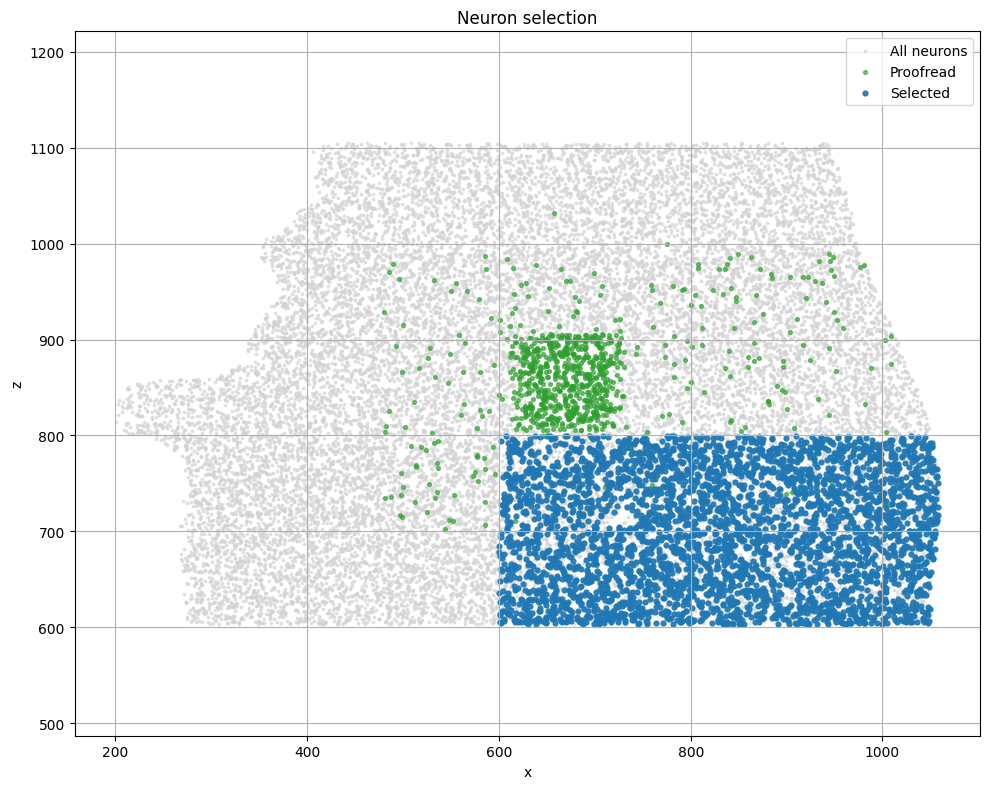

In [122]:
units_cleaned = clean_dataset(units)

selected_mask = (units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600) & (units_cleaned['selective_ori'] == 'True')

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    units.loc[selected_mask, "pt_position_x"],
    units.loc[selected_mask, "pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [123]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [124]:
E_L23 = units_cleaned[mask_exc & mask_l23 & selected_mask].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [125]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [126]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [127]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [128]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
        'pref_ori_fit'
    ]

    """if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')"""

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [129]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
        'pref_ori_fit'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    """if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')"""

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [130]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Ori_Diff']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(conn_dist)
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    features = [
        'ori_diff_polar'
    ]


    X = df[features].to_numpy(dtype=np.float32)
    y = df['label'].values

    return X, y, features

In [131]:
print(E_L23)
path, pre, post = pathways[0]
X, y, c = build_dataset(pre, post, synapses)
print(X)

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135772608763     930.297302     153.639816     719.039978   
1     864691135856593454     669.007080     172.089081     619.799988   
2     864691135992753857     666.839172     229.912170     659.080017   
3     864691136724515581     812.762817     118.751251     771.280029   
4     864691135182377986     813.191406     178.471863     773.520020   
...                  ...            ...            ...            ...   
2213  864691135644599279     888.780762      86.983772     613.840027   
2214  864691135468547212     650.351379     123.172989     799.400024   
2215  864691136362442466     788.676208     101.803474     795.919983   
2216  864691135429292592    1028.933472     105.669991     641.440002   
2217  864691136238038799     708.155273     187.977524     799.599976   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          none  L2/3  

In [132]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_3dselectiveori_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_lr3_normalised"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 50
PATIENCE = 10
LR = 1e-3
DIMS = [3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [133]:
# =========================
# Model
# =========================


class EmbeddingModel(nn.Module):
    def __init__(
        self,
        hidden=64
    ):
        super().__init__()


        self.mlp = nn.Sequential(
            nn.Linear(1, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, X):


        logits = self.mlp(X).squeeze(1)

        return logits

    def forward(self, X):
        return torch.sigmoid(
            self.forward_logits(X)
        )

In [135]:
from sklearn.preprocessing import StandardScaler

# =========================
# Data
# =========================

X, y, features = build_dataset(
    pre,
    post,
    synapses
)

X = X.astype(np.float32)
y = y.astype(np.float32)

print("n_pairs:", len(y))
print("positive rate:", y.mean())

# =========================
# Split indices
# =========================

n_total = len(y)

n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

indices = np.arange(n_total)

train_idx_set, val_idx_set, test_idx_set = random_split(
    indices,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_idx = np.array(train_idx_set.indices)

# =========================
# Normalize (fit on train only)
# =========================
""""
scaler = StandardScaler()

scaler.fit(
    X[train_idx]
)

X = scaler.transform(
    X
).astype(np.float32)
"""
# =========================
# Tensor conversion
# =========================

X = torch.tensor(
    X,
    dtype=torch.float32
)

y = torch.tensor(
    y,
    dtype=torch.float32
)

# =========================
# GPU
# =========================

X = X.to(DEVICE)

y = y.to(DEVICE)

# =========================
# Dataset
# =========================

dataset = TensorDataset(
    X,
    y
)

train_set = torch.utils.data.Subset(
    dataset,
    train_idx_set.indices
)

val_set = torch.utils.data.Subset(
    dataset,
    val_idx_set.indices
)

test_set = torch.utils.data.Subset(
    dataset,
    test_idx_set.indices
)

# =========================
# Dataloaders
# =========================

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train size:", len(train_set))
print("Val size:", len(val_set))
print("Test size:", len(test_set))

           pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0      864691134884804602  864691136267238900  1.048946         793.389404   
1      864691134885584634  864691135407772361  2.554404         754.282288   
2      864691134885584634  864691135772536059  1.211699         754.282288   
3      864691134885707258  864691135781844560  1.790273         958.058594   
4      864691134885761018  864691136811834227  0.492280         857.405273   
...                   ...                 ...       ...                ...   
29755  864691137020596590  864691135463400349  0.172142         775.809448   
29756  864691137054525558  864691135841697251  1.651666        1007.632446   
29757  864691137054551414  864691136663062238  0.969359         986.855530   
29758  864691137197717057  864691136091695028  0.232950         802.226379   
29759  864691137197842241  864691136664056542  0.030404         834.897034   

       pre_pt_position_z  pre_pref_ori_fit  post_pt_position_x 

In [136]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for X, yb in loader:

            logits = model.forward_logits(X)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [137]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [138]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [139]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [140]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel().to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for Z, yb in train_loader:
            logits = model.forward_logits(Z)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 3
dim=03 | epoch=000 | train_loss=0.3313 | val_loss=0.1387 | val_auc=0.5100
dim=03 | epoch=001 | train_loss=0.0929 | val_loss=0.0644 | val_auc=0.5100
dim=03 | epoch=002 | train_loss=0.0535 | val_loss=0.0465 | val_auc=0.5100
dim=03 | epoch=003 | train_loss=0.0438 | val_loss=0.0419 | val_auc=0.5100
dim=03 | epoch=004 | train_loss=0.0410 | val_loss=0.0403 | val_auc=0.5100
dim=03 | epoch=005 | train_loss=0.0398 | val_loss=0.0393 | val_auc=0.5100
dim=03 | epoch=006 | train_loss=0.0389 | val_loss=0.0385 | val_auc=0.5100
dim=03 | epoch=007 | train_loss=0.0383 | val_loss=0.0380 | val_auc=0.5100
dim=03 | epoch=008 | train_loss=0.0378 | val_loss=0.0376 | val_auc=0.5100
dim=03 | epoch=009 | train_loss=0.0375 | val_loss=0.0373 | val_auc=0.5100
dim=03 | epoch=010 | train_loss=0.0373 | val_loss=0.0372 | val_auc=0.5100
dim=03 | epoch=011 | train_loss=0.0372 | val_loss=0.0370 | val_auc=0.5096
dim=03 | epoch=012 | train_loss=0.0371 | val_loss=0.0370 | val_auc=0.5102
dim=03 | epoch=013 |

In [141]:
# =========================
# Load best geometry model
# =========================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DIM_TO_ANALYZE = 3
#CHECKPOINT_DIR = "checkpoints_3dgeo_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_lr3"

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

model = EmbeddingModel().to(DEVICE)

ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    ckpt["model_state_dict"]
)

model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Build dataset
# =========================

X, y, features = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

"""n_total = len(y)

n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

indices = np.arange(n_total)

train_set, val_set, test_set = random_split(
    indices,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_idx = np.array(train_set.indices)

scaler = StandardScaler()

scaler.fit(
    X[train_idx]
)

X = scaler.transform(
    X
)"""




X = torch.tensor(
    X,
    dtype=torch.float32
)

y = torch.tensor(
    y,
    dtype=torch.float32
)

print("X shape:", X.shape)
print("features:", features)
print("y shape:", y.shape)


# =========================
# Predict probabilities
# =========================

X = X.to(DEVICE)

with torch.no_grad():
    p_pred = model(X)

p_pred = (
    p_pred
    .detach()
    .cpu()
    .numpy()
)

print("p_pred shape:", p_pred.shape)


# =========================
# Compute distance from X
# =========================

X_np = (
    X
    .detach()
    .cpu()
    .numpy()
)

pre_xyz = X_np[:, 0:3]
post_xyz = X_np[:, 3:6]

distance = np.linalg.norm(
    pre_xyz - post_xyz,
    axis=1
)


# =========================
# Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "y": y.numpy(),
    "p_pred": p_pred,
})

df["bin"] = pd.cut(
    df["distance"],
    bins=40
)

curve = (
    df.groupby("bin")
    .agg(
        empirical_prob=("y", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)

centers = np.array([
    b.mid for b in curve.index
])


# =========================
# Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    centers,
    curve["predicted_prob"],
    marker="o",
    label="Geometry MLP predicted P(connection)"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Geometry MLP no normalised: P(connection) vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

BASELINE_DIR = "baselines"
os.makedirs(BASELINE_DIR, exist_ok=True)

baseline_path = os.path.join(
    BASELINE_DIR,
    "geometry_mlp_probability_vs_distance.csv"
)

curve = curve.copy()
curve["bin_center"] = centers

curve.to_csv(
    "baselines/geometry_mlp_probability_vs_distance.csv",
    index=False
)
curve.to_csv(baseline_path)

print("Saved:", baseline_path)

Loaded model for dim=3
Best epoch: 12
Best val loss: 0.0370
           pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0      864691134884804602  864691136267238900  1.048946         793.389404   
1      864691134885584634  864691135407772361  2.554404         754.282288   
2      864691134885584634  864691135772536059  1.211699         754.282288   
3      864691134885707258  864691135781844560  1.790273         958.058594   
4      864691134885761018  864691136811834227  0.492280         857.405273   
...                   ...                 ...       ...                ...   
29755  864691137020596590  864691135463400349  0.172142         775.809448   
29756  864691137054525558  864691135841697251  1.651666        1007.632446   
29757  864691137054551414  864691136663062238  0.969359         986.855530   
29758  864691137197717057  864691136091695028  0.232950         802.226379   
29759  864691137197842241  864691136664056542  0.030404         834.897034   

   

KeyError: "None of [Index(['ori_diff_polar'], dtype='object')] are in the [columns]"

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z2"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

NameError: name 'df_Z_full' is not defined

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [ ]:
for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
    corr = df_plot["z1"].corr(df_plot[coord])
    print(f"corr(z1, {coord}) = {corr:.3f}")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
N_BINS = 40
BATCH_SIZE = 32768



# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="o",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

In [ ]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

In [ ]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c}"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")